# Notebook 11: A Dynamic Hedge and a Copula

**References:** Chan, E. P. (2013). *Algorithmic Trading: Winning Strategies and Their Rationale*, chapter 3. Wiley. Liew, R. Q. and Wu, Y. (2013). Pairs trading: a copula approach. *Journal of Derivatives & Hedge Funds* 19(1), 12-30. Xie, W., Liew, R. Q., Wu, Y. and Zou, X. (2014). Pairs trading with copulas. SSRN working paper 2383185. Rad, H., Low, R. K. Y. and Faff, R. (2016). The profitability of pairs trading strategies: distance, cointegration and copula methods. *Quantitative Finance* 16(10), 1541-1558. Krauss, C. and Stübinger, J. (2015). Nonlinear dependence modeling with bivariate copulas: statistical arbitrage pairs trading on the S&P 100. IWQW Discussion Paper 15/2015.

Notebook 10 traded the gap between two books with a fixed hedge and a z-score. Two refinements are popular. A **Kalman filter** estimates the hedge as it goes, instead of assuming it stays put (Chan 2013). A **copula** replaces the gap with a model of how the two books' returns depend on each other, tails included (Liew and Wu 2013; Rad et al. 2016). This notebook runs both in the same books and asks whether they earn their keep, and then whether fitting their settings helps on markets the fit has not seen.

Each needs something the books of notebook 10 do not have. There beta is constant, so a dynamic hedge has nothing to track, and the common factor is Gaussian, so a copula has no shape to find. So `lob/pairs.py` gains two options, both off by default (notebook 10's runs are unchanged, number for number):

- **A drifting beta.** B moves $\beta_t$ times the common factor's moves, $dF_B = \beta_t\,dX + dU_B$, where $\beta_t$ is an Ornstein-Uhlenbeck process around its start. No fixed hedge stays right.
- **A stressed regime.** For some share of the time the common factor is more volatile, and perhaps falling, with the calm regime drifting the other way so that it stays a martingale. The books then move together mostly in their large moves: tail dependence.

The comparisons are like for like: the same span of each run (after every trader's warm-up), the same costs (what crossing the spread actually cost, in the books), and, where the question is the hedge, the same filter with its slope learned or frozen.

In [1]:
import itertools
import math
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from IPython.display import display
from quant_plots import Backtest, scorecard, signal_chart

from lob.analysis.plotting import set_style
from lob.copulas import Margin, fit_copula, pseudo_observations
from lob.pairs import (A, B, AnchoredZIModel, CopulaTrader, FairValues, KalmanHedge, KalmanTrader, PairMarket,
                       PairsTrader, score_trader)

set_style()

SEEDS = range(1, 9)
UNITS = 20_000  # time units in a run
SKIP = 2_500    # compared from here on: every trader's warm-up is over by then
LEVEL = 3_000.0  # where both books start: far above the floor of one tick, even with a strong common factor
CAPITAL = 40_000.0  # ticks x lots, for the cards: a third more than 5 lots in each book hold
DEEP = dict(limit_rate=40.0)  # four times the limit orders, so that a fast common factor does not strip the books


def market(seed, traders=(), deep=False, **settings):
    models = (AnchoredZIModel(**DEEP), AnchoredZIModel(**DEEP)) if deep else None
    return PairMarket(FairValues(level_a=LEVEL, level_b=LEVEL, **settings), models=models, seed=seed, traders=traders)


class PerfectHedge(KalmanTrader):
    # What no trader could do, as a ceiling: it reads the true gap and holds the true beta, with the same filter
    # on the level as the others.
    book = None

    def observe(self, mid_a, mid_b):
        signal = super().observe(0.0, self.book.fair.gap_of(mid_a, mid_b))
        self.hedge = self.book.fair.beta
        return signal


def measured(make, seed, deep=False, **settings):
    # One trader alone in a market. Everything over the same span: from SKIP to the end of the run.
    trader = make()
    m = market(seed, (trader,), deep=deep, **settings)
    if isinstance(trader, PerfectHedge):
        trader.book = m
    m.run(SKIP, every=SKIP)
    value = trader.value(m.mark(A), m.mark(B))
    cost, lots, entries = trader.spread_paid, trader.lots, trader.entries
    d = m.run(UNITS)
    net = d['pos_a_0'].to_numpy(float) + d['beta'].to_numpy() * d['pos_b_0'].to_numpy(float)
    holding = d['pos_b_0'].to_numpy(float) != 0
    from_common = float(np.sum(net[:-1] * np.diff(d['common'].to_numpy())))
    pnl = trader.value(m.mark(A), m.mark(B)) - value
    paid = trader.spread_paid - cost
    return {'P&L': pnl, 'before costs': pnl + paid, 'costs': paid, 'lots': trader.lots - lots,
            'entries': trader.entries - entries, 'from the common factor': from_common,
            'net delta': float(np.sqrt(np.mean(net[holding] ** 2))) if holding.any() else 0.0,
            'hedge error': float(np.sqrt(np.mean((d['hedge_0'].to_numpy(float) - d['beta'].to_numpy()) ** 2)))}


def table(rows, by):
    # Mean over seeds, with its standard error and how many seeds came out positive.
    frame = pd.DataFrame(rows)
    out = frame.groupby(by, sort=False).agg(
        pnl=('P&L', 'mean'), se=('P&L', lambda p: p.std() / math.sqrt(len(p))),
        positive=('P&L', lambda p: f'{(p > 0).sum()} of {len(p)}'), before_costs=('before costs', 'mean'),
        costs=('costs', 'mean'), lots=('lots', 'mean'), entries=('entries', 'mean'), net_delta=('net delta', 'mean'),
        hedge_error=('hedge error', 'mean'), common_sd=('from the common factor', 'std'))
    out['cost_a_lot'] = out.costs / out.lots
    out = out.drop(columns='lots')
    return frame, out.round({'pnl': 0, 'se': 0, 'before_costs': 0, 'costs': 0, 'entries': 1, 'net_delta': 2,
                             'hedge_error': 2, 'common_sd': 0, 'cost_a_lot': 2})

## 1. The Filter

The filter treats the pair as a regression whose slope and level may drift (Chan 2013):

$$y_t = \alpha_t + \beta_t\,(x_t - \bar x_t) + e_t, \qquad \beta_t = \beta_{t-1} + w^\beta_t, \qquad \alpha_t = \alpha_{t-1} + w^\alpha_t,$$

with $y$ and $x$ the mids of B and A. At each decision it predicts $y_t$, takes the error $v_t$, and moves both estimates by the Kalman gain. The slope is the hedge. The error over its usual size is the z-score it trades: beyond $\pm 2$ it takes a position, and at 0 it goes flat.

Three details differ from the usual form. The regressor is measured from a pivot near the prices, since with $x$ near 3,000 and a pivot of 0 a tiny change of slope moves the fit by more than the gap's whole range unless the level moves the other way at once. Its one tuning setting is a **memory** $M$ in decisions, which sets the state noise at $q = r/M^2$, the time constant of the filter; Chan's $\delta$ and $V_e$ set the same ratio, in units that depend on the prices. And the "usual size" is a running average of the squared errors, not the filter's own variance, which assumes white noise and a known $r$: with a persistent gap that gave z-scores with a standard deviation near 2, so an entry level of 2 was really 1.

`tests/test_pairs.py` holds the recursion to three independent results: with no state noise it is exactly least squares; with a flat regressor it reaches the known steady gain; and its final state and uncertainty equal the Gaussian posterior of the whole path, solved in one go. Here is what it does with data it can handle: a clean regressor, a slope that drifts, and white noise.

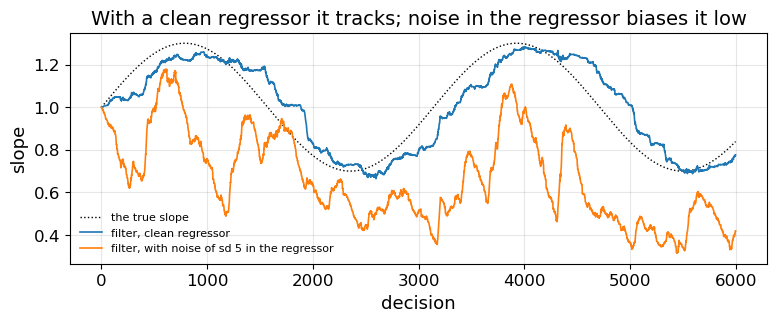

Mean slope after the start: true 0.99, clean 1.00, noisy 0.65


In [2]:
def synthetic(noise_in_x, seed=3, n=6_000):
    rng = np.random.default_rng(seed)
    x = 3000 + np.cumsum(rng.normal(size=n))
    beta = 1 + 0.3 * np.sin(np.arange(n) / 500)
    y = 3000 + np.r_[0, np.cumsum(beta[:-1] * np.diff(x))] + rng.normal(scale=2.0, size=n)
    seen = x + rng.normal(scale=noise_in_x, size=n) if noise_in_x else x
    f = KalmanHedge(1.0, y[0], seen[0], 1 / 400 / 25, 4 / 200, 4 / 200 ** 2 / 25, 4 / 200 ** 2, 4.0)
    path = []
    for a, b in zip(seen, y, strict=True):
        f.move_pivot(f.pivot + (a - f.pivot) / 200)
        f.update(a, b)
        path.append(f.beta)
    return beta, np.array(path)


fig, ax = plt.subplots(figsize=(9, 3))
beta, clean = synthetic(0.0)
_, noisy = synthetic(5.0)
ax.plot(beta, color='k', lw=1, ls=':', label='the true slope')
ax.plot(clean, lw=1.2, label='filter, clean regressor')
ax.plot(noisy, lw=1.2, label='filter, with noise of sd 5 in the regressor')
ax.set(xlabel='decision', ylabel='slope',
       title='With a clean regressor it tracks; noise in the regressor biases it low')
ax.legend(frameon=False, fontsize=8)
plt.show()
print(f'Mean slope after the start: true {beta[500:].mean():.2f}, clean {clean[500:].mean():.2f}, '
      f'noisy {noisy[500:].mean():.2f}')

That is the first of two problems the books pose. A's mid is not the common factor: it carries A's own part, whose variance $\sigma_u^2 / 2\kappa$ is 23 ticks squared by default. This is the attenuation of notebook 10, which measured least-squares hedges of 0.72 to 0.83 over 4,000 units, 0.92 over 16,000 and 0.98 over 64,000. The ratio $v / (v + \sigma_u^2/2\kappa)$, with $v = \sigma^2 W/6$ the variance a random walk builds up in a window of $W$, gives 0.72, 0.91 and 0.98 at those lengths: it accounts for them.

The second problem is that the gap, which is the regression's noise, is persistent. With a half-life of 50 its memory $\tau = 50 / \ln 2$ leaves about $W/2\tau$ independent observations in a window of $W$, not $W$, and the slope's standard error is about

$$\mathrm{se}(\hat\beta) \approx \frac{\mathrm{sd}(\text{gap})}{\sigma\sqrt{W/6}} \sqrt{\frac{2\tau}{W}},$$

which falls as the common factor's volatility $\sigma$ rises. Tracking a drifting beta wants a short memory, and this wants a long one. Here are the hedges from the books, with beta fixed and beta drifting, beside rolling least squares and rolling total least squares (which allows for noise in both prices).

Root mean square error of the hedge against the true beta, after the first 4,000 units (6 seeds):
                      beta fixed, common 0.3  beta fixed, common 1  beta drifts 0.3, common 1  beta drifts 0.5, common 2
fixed at the start                     0.000                 0.000                      0.249                      0.487
Kalman, memory 1,000                   0.489                 0.143                      0.234                      0.322
Kalman, memory 3,000                   0.313                 0.067                      0.277                      0.441
rolling OLS, 1,000                     0.718                 0.247                      0.279                      0.261
rolling OLS, 2,000                     0.561                 0.144                      0.236                      0.325
rolling OLS, 4,000                     0.412                 0.081                      0.271                      0.398
rolling TLS, 1,000                   115.196           

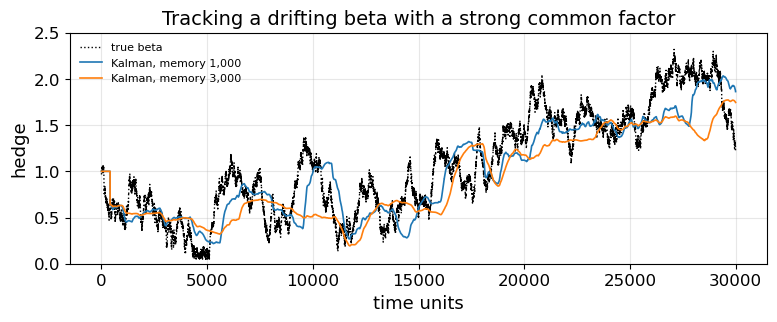

In [3]:
def hedge_paths(seed, **settings):
    fast, slow = (KalmanTrader(window=400, memory=m, entry=1e6, exit=0.0) for m in (1000.0, 3000.0))  # never trades
    d = market(seed, (fast, slow), **settings).run(30_000).dropna(subset=['mid_a', 'mid_b'])
    a, b, beta = pd.Series(d.mid_a.to_numpy(float)), pd.Series(d.mid_b.to_numpy(float)), d.beta.to_numpy()

    def rmse(hedge):
        return float(np.sqrt(np.nanmean((np.asarray(hedge, dtype=float)[4000:] - beta[4000:]) ** 2)))

    out = {'fixed at the start': rmse(np.full(len(beta), beta[0])), 'Kalman, memory 1,000': rmse(d.hedge_0),
           'Kalman, memory 3,000': rmse(d.hedge_1)}
    for w in (1000, 2000, 4000):
        out[f'rolling OLS, {w:,}'] = rmse(a.rolling(w).cov(b) / a.rolling(w).var())
    for w in (1000, 4000):
        va, vb, c = a.rolling(w).var(), b.rolling(w).var(), a.rolling(w).cov(b)
        out[f'rolling TLS, {w:,}'] = rmse(((vb - va) + np.sqrt((vb - va) ** 2 + 4 * c ** 2)) / (2 * c))
    out['mean, memory 1,000'] = float(np.mean(d.hedge_0.to_numpy(float)[4000:] / beta[4000:]))
    return out, d


TRACKING = {'beta fixed, common 0.3': dict(volatility=0.3), 'beta fixed, common 1': dict(volatility=1.0),
            'beta drifts 0.3, common 1': dict(volatility=1.0, beta_sd=0.3, beta_half_life=2000.0),
            'beta drifts 0.5, common 2': dict(volatility=2.0, beta_sd=0.5, beta_half_life=2000.0)}
tracked = Parallel(n_jobs=-1)(delayed(hedge_paths)(seed, **kw) for kw in TRACKING.values() for seed in range(1, 7))
errors = pd.DataFrame({name: pd.DataFrame([r[0] for r in tracked[i * 6:(i + 1) * 6]]).mean()
                       for i, name in enumerate(TRACKING)})
print('Root mean square error of the hedge against the true beta, after the first 4,000 units (6 seeds):')
print(errors.drop(index='mean, memory 1,000').round(3).to_string())
print("\nThe filter's mean hedge over the true beta:", errors.loc['mean, memory 1,000'].round(2).to_dict())

tau, gap_sd, own_var = 50 / math.log(2), FairValues().gap_sd, 0.8 ** 2 / (2 * math.log(2) / 50)
print('\nPredicted for least squares with beta fixed and a common volatility of 1, noise and attenuation together:')
for w in (1000, 2000, 4000):
    se = gap_sd / math.sqrt(w / 6) * math.sqrt(2 * tau / w)
    bias = 1 - (w / 6) / (w / 6 + own_var)
    measured_error = errors.loc[f'rolling OLS, {w:,}', 'beta fixed, common 1']
    print(f"  window {w:,}: {math.hypot(se, bias):.3f}, against {measured_error:.3f}")

path = tracked[3 * 6][1]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(path.time, path.beta, color='k', lw=1, ls=':', label='true beta')
ax.plot(path.time, path.hedge_0.astype(float), lw=1.2, label='Kalman, memory 1,000')
ax.plot(path.time, path.hedge_1.astype(float), lw=1.2, label='Kalman, memory 3,000')
ax.set(xlabel='time units', ylabel='hedge', title='Tracking a drifting beta with a strong common factor', ylim=(0, 2.5))
ax.legend(frameon=False, fontsize=8)
plt.show()

The filter behaves like rolling least squares over about twice its memory, as an exponential average of time constant $M$ has the mean age of a window of $2M$. So it is no sharper a tool than a rolling regression; its advantage is that it needs no window of history to recompute. Allowing for noise in both prices does not rescue it: total least squares is about the same where it is stable, and wildly unstable where the covariance in its denominator is small.

With a common volatility of 1 and a beta that drifts by 0.3, no memory tracks beta much better than a fixed hedge does: what a short memory gains in speed it loses in noise. Only with a common volatility of 2, where the books move together closely, does the filter clearly beat a fixed hedge.

## 2. Does the Hedge Pay?

The direct test holds everything else equal. Each trader below uses the same filter on the level, with the same memory, entry and exit, so its z-score means the same thing:

- **fixed hedge**: the slope frozen at beta's starting value of 1, the filter on the level alone;
- **Kalman**: the slope learned, and followed while holding;
- **Kalman, held**: the slope learned, but kept as it was on entry until the next one;
- **perfect hedge**: what no trader could do, as a ceiling: it reads the true gap and holds the true beta;
- and notebook 10's z-score, with a window of 2,000 (the same mean age).

Five markets: beta fixed or drifting, with a common volatility of 1 or 2. With a common volatility of 2 the books are shown both as they are and four times as deep, because a fast factor strips the standard books' quotes and crossing them costs about twice as much for everyone (see *cost a lot*).

In [4]:
K = dict(window=400, entry=2.0, exit=0.0, size=5)
HEDGES = {
    'z-score, window 2,000': lambda: PairsTrader(window=2000, entry=2.0, exit=0.0, size=5),
    'fixed hedge': lambda: KalmanTrader(memory=1000.0, learn_hedge=False, **K),
    'Kalman': lambda: KalmanTrader(memory=1000.0, **K),
    'Kalman, held': lambda: KalmanTrader(memory=1000.0, rebalance=False, **K),
    'perfect hedge': lambda: PerfectHedge(memory=1000.0, learn_hedge=False, **K),
}
HEDGE_MARKETS = {
    'beta fixed, common 1': dict(volatility=1.0),
    'beta drifts, common 1': dict(volatility=1.0, beta_sd=0.3, beta_half_life=2000.0),
    'beta drifts, common 2': dict(volatility=2.0, beta_sd=0.5, beta_half_life=2000.0),
    'beta fixed, common 2, deep': dict(volatility=2.0, deep=True),
    'beta drifts, common 2, deep': dict(volatility=2.0, beta_sd=0.5, beta_half_life=2000.0, deep=True),
}


def hedge_run(name, market_name, seed):
    return {'market': market_name, 'trader': name, 'seed': seed,
            **measured(HEDGES[name], seed, **HEDGE_MARKETS[market_name])}


rows = Parallel(n_jobs=-1)(delayed(hedge_run)(name, market_name, seed) for market_name in HEDGE_MARKETS
                           for name in HEDGES for seed in SEEDS)
hedge_frame, hedge_table = table(rows, ['market', 'trader'])
print(hedge_table.to_string())

                                                      pnl     se positive  before_costs   costs  entries  net_delta  hedge_error  common_sd  cost_a_lot
market                      trader                                                                                                                     
beta fixed, common 1        z-score, window 2,000  1085.0   51.0   8 of 8        1910.0   825.0     30.8       0.00         0.00        0.0        1.34
                            fixed hedge            1055.0   42.0   8 of 8        1993.0   938.0     33.8       0.00         0.00        0.0        1.39
                            Kalman                  655.0   65.0   8 of 8        1586.0   931.0     34.9       0.84         0.15       45.0        1.33
                            Kalman, held            723.0   64.0   8 of 8        1714.0   992.0     38.2       0.77         0.15       96.0        1.35
                            perfect hedge          1055.0   42.0   8 of 8        1993.0 

**What the columns say.** *P&L* and *costs* are over the same span of each run, costs being what crossing the spread cost in the books. *Net delta* is the root mean square, while holding, of what the position stands to gain per tick of the common factor, $q_A + \beta_t q_B$, in lots: what a hedge exists to remove. *Common sd* is the standard deviation across seeds of the P&L that exposure made, which is luck.

Three checks first. With beta fixed, the perfect hedge and the fixed hedge are the same trader and come out equal to the last digit. With beta fixed the true hedge is 1, so both have no net delta. And the perfect hedge's net delta when beta drifts is only what rounding to whole lots leaves.

**With beta fixed, learning the hedge costs money.** It trades on an estimate that is off, attenuated and noisy, where a fixed hedge would have been exactly right.

**With beta drifting and a common volatility of 1, there is nothing to win.** Even the perfect hedge barely beats the fixed one after costs: knowing beta gives it more trades and more before costs, and the costs take it back. The filter does worse than either.

**With beta drifting and a common volatility of 2, it depends on the book.** In the standard books crossing costs so much that nobody makes much: the filter earns several times what a fixed hedge does before costs, and pays nearly all of it to the spread. **In deep books the filter pays.** This is where it tracks beta, as section 1 said, and where a wrong hedge lets a fast common factor into the gap and hides the signal. It gets a good part of the way to the ceiling, and it is the only regime here where it clearly beats a fixed hedge. The z-score with a long window is not clearly behind it even there: its rolling mean absorbs some of the drift.

**Following the hedge while holding adds nothing measurable** over setting it on entry: a position lasts far less time than beta takes to move, and each adjustment crosses a spread.

Here is that last market in a backtest's terms, with the fixed hedge beside it.

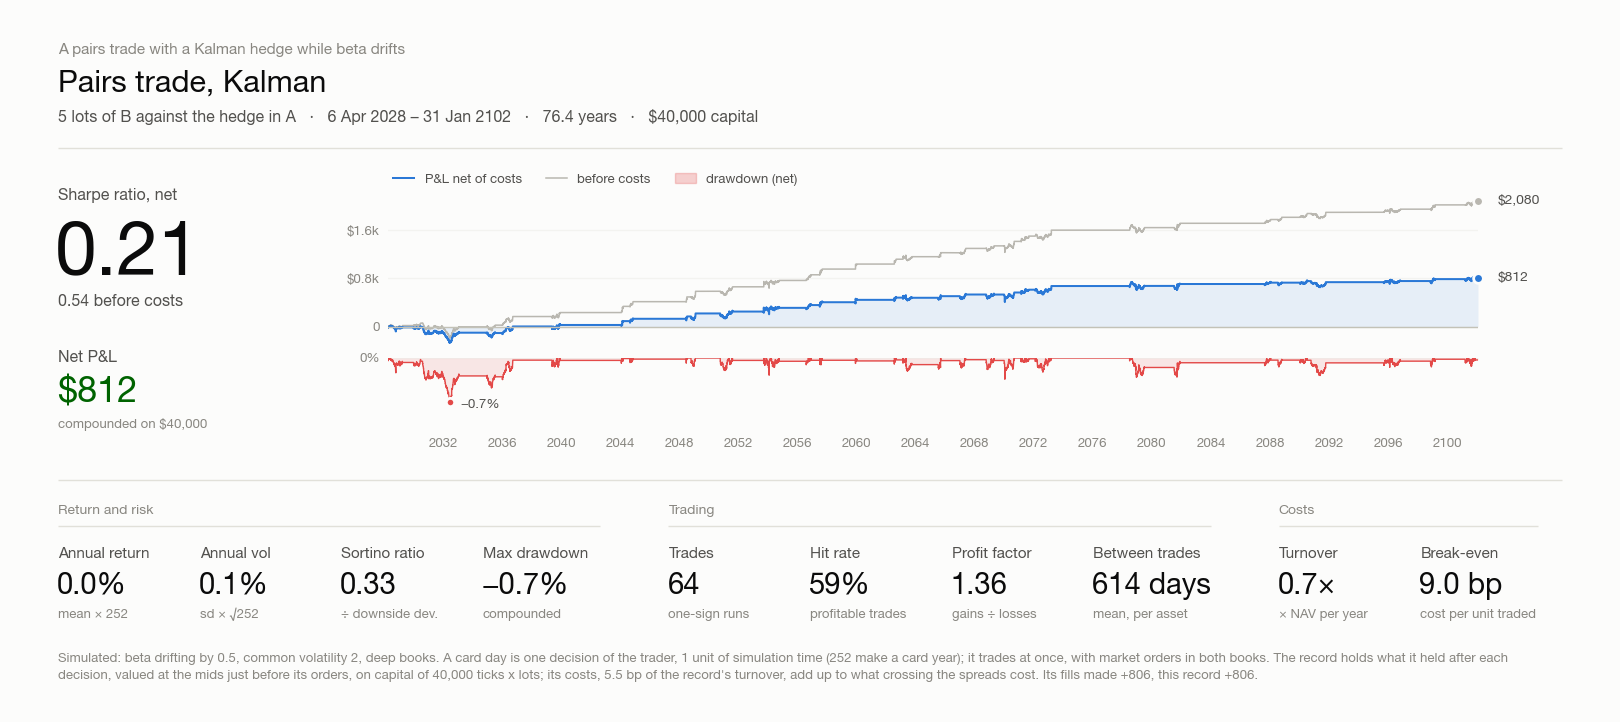

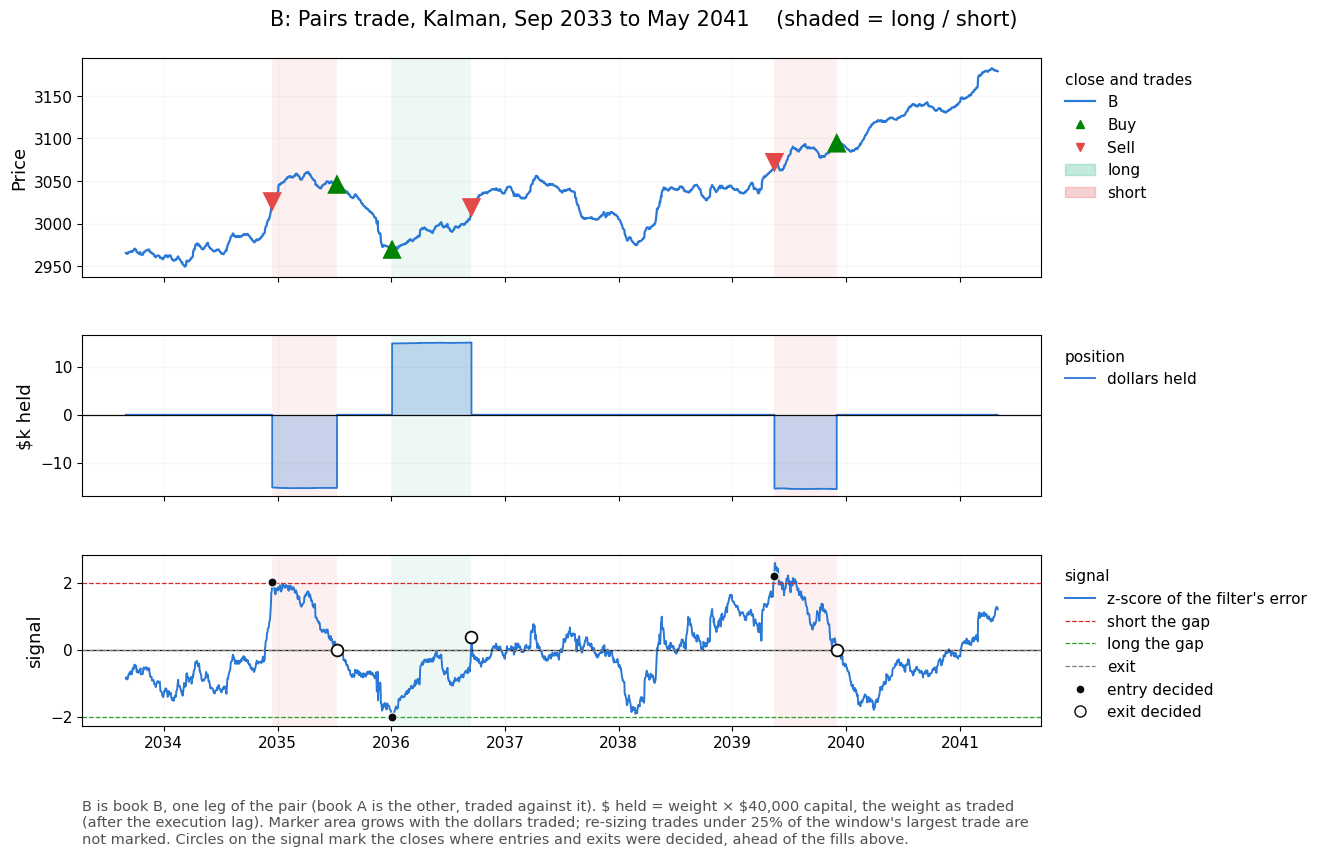

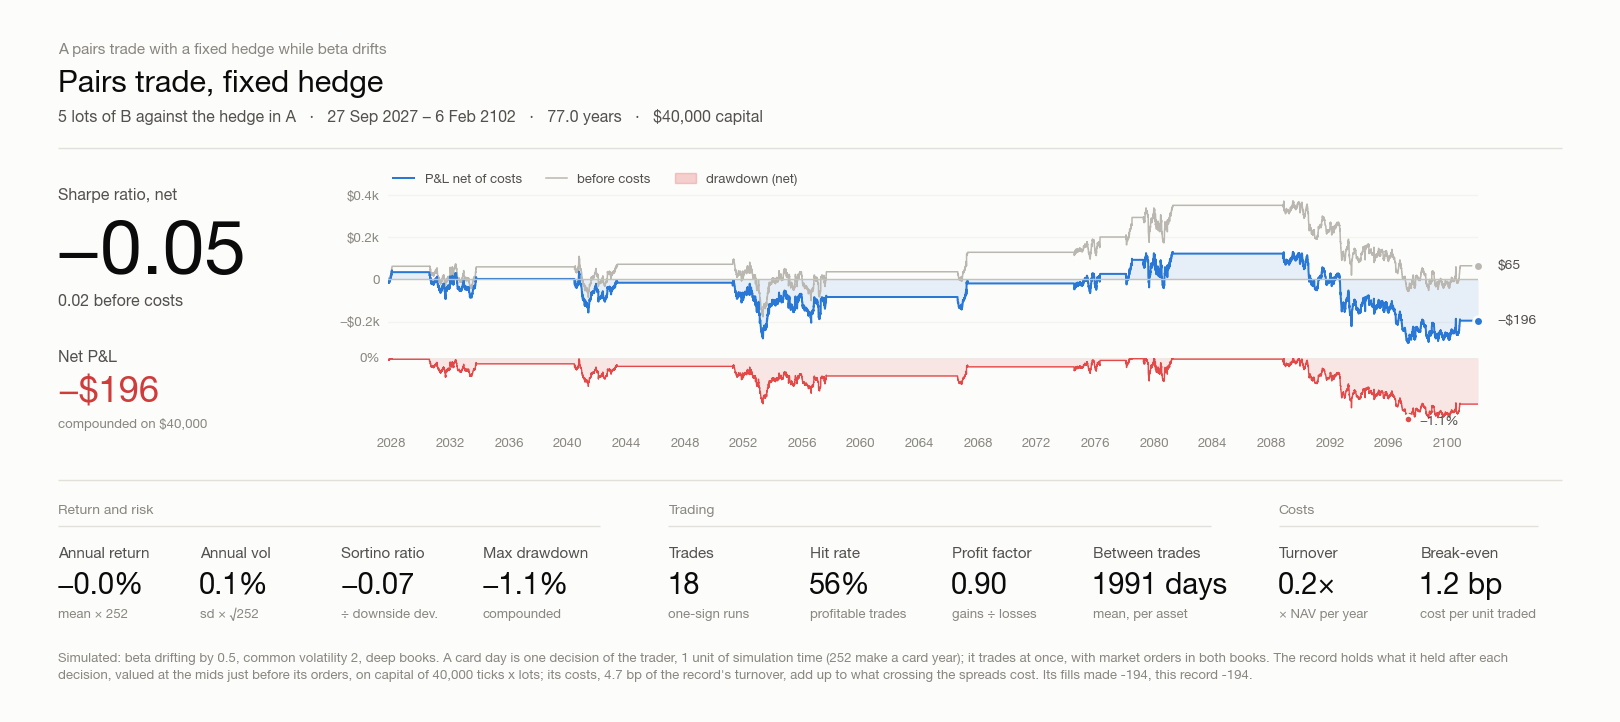

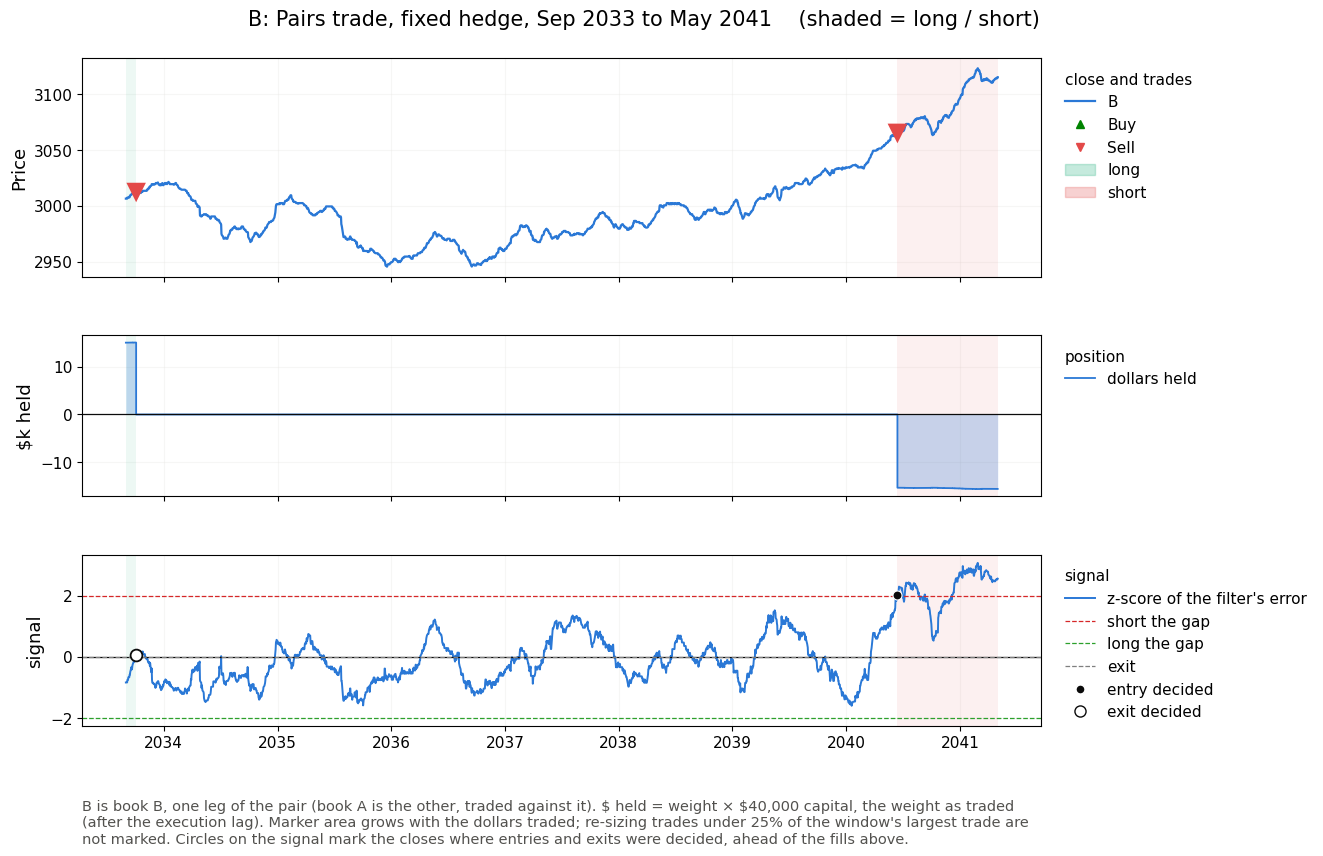

In [5]:
def decision_record(trader):
    h = pd.DataFrame(trader.history, columns=['time', 'mid_a', 'mid_b', 'pos_a', 'pos_b', 'z', 'target'])
    days = pd.bdate_range('2026-01-01', periods=len(h))
    mids = pd.DataFrame({'A': h.mid_a.to_numpy(), 'B': h.mid_b.to_numpy()}, index=days)
    held = pd.DataFrame({'A': (h.pos_a * h.mid_a).to_numpy() / CAPITAL, 'B': (h.pos_b * h.mid_b).to_numpy() / CAPITAL},
                        index=days)
    returns = mids.pct_change().fillna(0.0)
    turnover = Backtest(held, returns, cost_bp=0.0).turnover.sum() * CAPITAL
    cost_bp = trader.spread_paid / turnover * 1e4  # the record pays, in all, what crossing the spreads cost
    target = pd.Series(h.target.to_numpy(), index=days)
    change = target.ne(target.shift(1).fillna(0))
    z = pd.Series(pd.to_numeric(h.z).to_numpy(), index=days)
    return (Backtest(held, returns, cost_bp=cost_bp), mids, held, z, list(days[change & target.ne(0)]),
            list(days[change & target.eq(0)]), cost_bp)


def card(trader, m, strategy, detail, title, setting, signal_label, levels, start=2000, end=4000, per_unit=1):
    bt, mids, held, z, entries, exits, cost_bp = decision_record(trader)
    fills = trader.value(m.mark(A), m.mark(B))
    note = (f"Simulated: {setting}. A card day is one decision of the trader, {per_unit} "
            f"unit{'' if per_unit == 1 else 's'} of simulation time (252 make a card year); it trades at once, with "
            f"market orders in both books. The record holds what it held after each decision, valued at the mids just "
            f"before its orders, on capital of {CAPITAL:,.0f} ticks x lots; its costs, {cost_bp:.1f} bp of the "
            f"record's turnover, add up to what crossing the spreads cost. Its fills made {fills:+,.0f}, this record "
            f"{bt.net.sum() * CAPITAL:+,.0f}.")
    display(scorecard(bt, strategy, detail=detail, capital=CAPITAL, title=title, footnote=note))
    signal_chart('B', mids['B'], held['B'], z, capital=CAPITAL, strategy=strategy, signal_label=signal_label,
                 levels=levels, entries=entries, exits=exits, start=mids.index[start], end=mids.index[end],
                 asset_name='book B, one leg of the pair (book A is the other, traded against it)')
    plt.show()
    return fills, bt.net.sum() * CAPITAL


DRIFTING = HEDGE_MARKETS['beta drifts, common 2, deep']
Z_LEVELS = [(2.0, 'C3', 'short the gap'), (-2.0, 'C2', 'long the gap'), (0.0, 'C7', 'exit')]
agreement = []
for label, freeze in (('Kalman', False), ('fixed hedge', True)):
    trader = KalmanTrader(memory=1000.0, learn_hedge=not freeze, record=True, **K)
    m = market(1, (trader,), **DRIFTING)
    m.run(UNITS, every=1000.0)
    agreement.append(card(trader, m, f'Pairs trade, {label}', '5 lots of B against the hedge in A',
                          f'A pairs trade with a {"fixed" if freeze else "Kalman"} hedge while beta drifts',
                          'beta drifting by 0.5, common volatility 2, deep books', "z-score of the filter's error",
                          Z_LEVELS))

## 3. What the Books' Returns Look Like Through a Copula

A copula separates how two variables depend on each other from each one's own distribution. Rank each book's returns over a window, so that each is uniform, and what is left is the dependence. Fit a family to the ranks (the method here is canonical maximum likelihood, with the family chosen by AIC): the Gaussian, Student t and Frank are symmetric; Clayton and rotated Gumbel have dependent lower tails; Gumbel and rotated Clayton upper ones. `tests/test_copulas.py` checks each family's conditional probability against the derivative of its distribution function, its density against the joint density, and its parameters and AIC against samples.

Before trading on it, does this find what is there? These markets have dependence of known shape, and the data are the mids of the books, half ticks and all: a common factor with no regimes, stress in both directions, and stress with a falling market.

                                   chosen   tau  corr  lower_tail  upper_tail  aic_below_gaussian
market                                                                                           
no regimes, common 1  Gaussian 5, Frank 3  0.32  0.42        0.00        0.00                1.72
stress, both ways             Student t 8  0.16  0.46        0.13        0.13              140.03
stress, falling                 Clayton 8  0.21  0.56        0.35        0.00              396.26


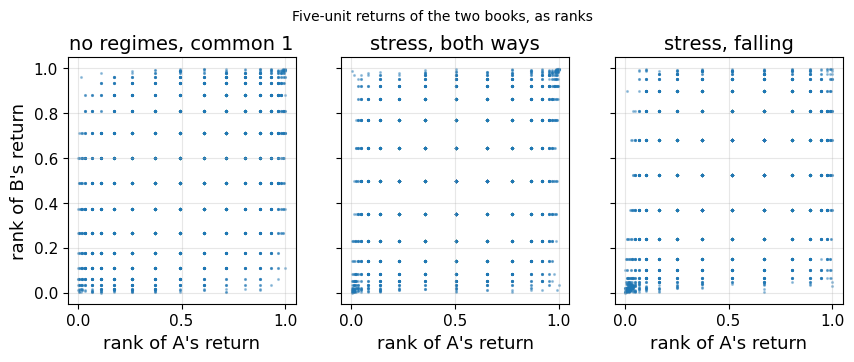

In [6]:
STRESS = dict(volatility=0.3, stress_share=0.1, stress_volatility=3.0, stress_length=50.0)
COPULA_MARKETS = {'no regimes, common 1': dict(volatility=1.0), 'stress, both ways': STRESS,
                  'stress, falling': {**STRESS, 'stress_drift': -1.0}}


def returns_of(seed, every=5, units=UNITS, **settings):
    d = market(seed, **settings).run(units, every=float(every)).dropna(subset=['mid_a', 'mid_b'])
    return np.diff(d.mid_a.to_numpy(float)), np.diff(d.mid_b.to_numpy(float))


def family_run(name, seed):
    ra, rb = returns_of(seed, **COPULA_MARKETS[name])
    fit = fit_copula(pseudo_observations(ra), pseudo_observations(rb))
    lower, upper = fit.copula.tail_dependence()
    gaussian = next(row[2] for row in fit.table if row[0] == 'Gaussian')
    return {'market': name, 'seed': seed, 'family': fit.copula.name, 'tau': fit.tau, 'corr': np.corrcoef(ra, rb)[0, 1],
            'lower tail': lower, 'upper tail': upper, 'AIC below the Gaussian': gaussian - fit.aic}


families = pd.DataFrame(Parallel(n_jobs=-1)(delayed(family_run)(name, seed) for name in COPULA_MARKETS
                                            for seed in SEEDS))
print(families.groupby('market', sort=False).agg(
    chosen=('family', lambda f: ', '.join(f'{k} {v}' for k, v in f.value_counts().items())), tau=('tau', 'mean'),
    corr=('corr', 'mean'), lower_tail=('lower tail', 'mean'), upper_tail=('upper tail', 'mean'),
    aic_below_gaussian=('AIC below the Gaussian', 'mean')).round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharex=True, sharey=True)
for ax, (name, kw) in zip(axes, COPULA_MARKETS.items(), strict=True):
    ra, rb = returns_of(1, **kw)
    ax.scatter(pseudo_observations(ra), pseudo_observations(rb), s=1.5, alpha=0.35, rasterized=True)
    ax.set(title=name, xlabel="rank of A's return")
axes[0].set_ylabel("rank of B's return")
fig.suptitle('Five-unit returns of the two books, as ranks', y=1.03, fontsize=10)
plt.show()

It does. With no regimes the Gaussian and the families near it are nearly tied, as they should be. With stress in both directions the Student t wins in every seed by a wide margin, with equal tails: the family Rad et al. (2016) find most often in real stocks (62% of their pairs). With a falling stress the dependence is one-sided: a lower tail and no upper one, in the bottom-left corner of the plot. Correlation alone cannot tell these markets apart: their Pearson correlations are close, while Kendall's tau is lower in both stressed markets, whose dependence sits in a few large moves. (The grid in the plots is the half ticks: tied returns share a rank.)

## 4. The Copula's Rule

The rule is Rad et al.'s (2016), after Xie et al. (2014). Fit the copula over a formation window of returns, then for each new pair of returns take the two conditional probabilities and their mispricing indices,

$$m_A = P(U_A \le u_A \mid U_B = u_B) - 0.5, \qquad m_B = P(U_B \le u_B \mid U_A = u_A) - 0.5,$$

how high each book's return was for what the other's did. They accumulate from 0 into flags $M_A$ and $M_B$. When one flag is above $D$ and the other below $-D$ the trader takes a position against the difference, and it unwinds when both have returned to zero (not necessarily at once: that is this notebook's reading of "both"). At the end of each trading period it closes what is open, fits again and starts the flags from 0. Rad et al. "arbitrarily" set $D = 0.5$ on daily returns.

Here returns are over 5 units of time, which gets away from the half-tick grid and the bid-ask bounce. The window is 400 decisions, the trading period 200 (their 12 and 6 months are the same 2 to 1), and margins are empirical, as prices on half ticks tie; Rad et al. fit parametric ones, logistic in most cases.

**Something the rule takes on trust.** Krauss and Stübinger (2015) point out that Rad et al. do not test whether the flags mean-revert. Under the right copula with independent returns they cannot: $h(U_A \mid U_B)$ is then uniform (the test suite checks this), and independent of the past, so each flag is a random walk. All the mean reversion must come from the returns' own dependence on the past. In these books it exists, since the gap reverts. Is it in the flags?

The test below computes the flags on one long run with no fresh start, in two ways: with one window's margins and copula, as the trader has them just after a fit, and with the same copula and margins centered on the whole run, which no trader could have. Then, as the trader does it, afresh every 200 decisions.

                                          0       1        2         3       4        5        6        7
end, one window                       -9.37   -9.96    16.88     62.20   13.54    37.05    16.30    28.92
half-life, one window               1211.81  722.90  3406.46  23464.82  973.80  9685.15  3241.50  6384.43
corr with the gap, one window          0.37    0.30     0.11      0.08    0.29    -0.06     0.23     0.08
end, centered                         -2.77   -4.16    -1.15      2.23   -6.84     3.91     5.04    -1.12
half-life, centered                  477.61  287.84   590.42    457.83  658.91   489.79   611.71   316.93
corr with the gap, centered            0.53    0.45     0.38      0.32    0.26     0.48     0.42     0.52
half-life of the gap                  80.65   73.39    69.96     82.40   71.35    73.25    73.48    67.74
corr with the gap's change, afresh     0.92    0.89     0.91      0.93    0.92     0.91     0.92     0.93

Medians: {'end, one window': 16.59, 'half-lif

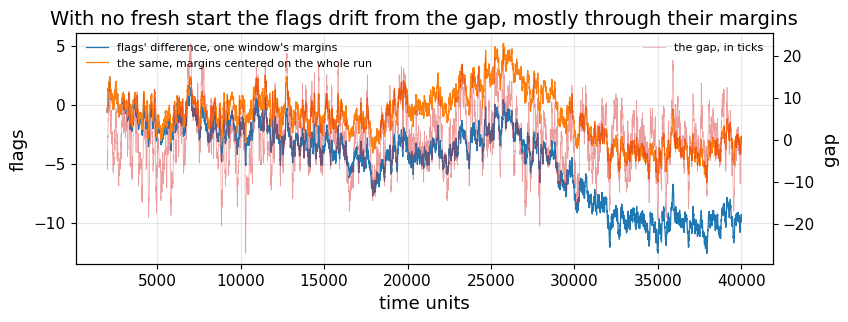

In [7]:
def half_life_of(x, lag=4, every=5):
    x = np.asarray(x) - np.mean(x)
    phi = np.corrcoef(x[:-lag], x[lag:])[0, 1]
    return -lag * every * math.log(2) / math.log(phi) if 0 < phi < 1 else np.inf


def flags_of(copula_fit, u, v):
    return np.cumsum(copula_fit.h(v, u) - copula_fit.h(u, v)) / 2  # half the difference of the flags


def flags_run(seed, units=40_000, window=400, period=200):
    d = market(seed, volatility=1.0).run(units, every=5.0).dropna(subset=['mid_a', 'mid_b'])
    ra, rb = np.diff(d.mid_a.to_numpy(float)), np.diff(d.mid_b.to_numpy(float))
    gap = d.gap.to_numpy(float)[1:]
    fit = fit_copula(pseudo_observations(ra[:window]), pseudo_observations(rb[:window])).copula
    margin_a, margin_b = Margin(ra[:window]), Margin(rb[:window])
    one_window = flags_of(fit, np.array([margin_a(x) for x in ra[window:]]),
                          np.array([margin_b(x) for x in rb[window:]]))
    centered = flags_of(fit, pseudo_observations(ra)[window:], pseudo_observations(rb)[window:])
    within = []
    for start in range(window, len(ra) - period, period):
        past_a, past_b = ra[start - window:start], rb[start - window:start]
        refit = fit_copula(pseudo_observations(past_a), pseudo_observations(past_b)).copula
        m_a, m_b = Margin(past_a), Margin(past_b)
        flags = flags_of(refit, np.array([m_a(x) for x in ra[start:start + period]]),
                         np.array([m_b(x) for x in rb[start:start + period]]))
        within.append(np.corrcoef(flags, gap[start:start + period] - gap[start - 1])[0, 1])
    level = gap[window:]
    return {'end, one window': one_window[-1], 'half-life, one window': half_life_of(one_window),
            'corr with the gap, one window': np.corrcoef(one_window, level)[0, 1],
            'end, centered': centered[-1], 'half-life, centered': half_life_of(centered),
            'corr with the gap, centered': np.corrcoef(centered, level)[0, 1],
            'half-life of the gap': half_life_of(level),
            "corr with the gap's change, afresh": float(np.nanmedian(within))}, (
                d.time.to_numpy()[window + 1:], one_window, centered, level)


flag_runs = Parallel(n_jobs=-1)(delayed(flags_run)(seed) for seed in SEEDS)
stats = pd.DataFrame([r[0] for r in flag_runs])
print(stats.round(2).T.to_string())
print('\nMedians:', stats.median().round(2).to_dict())

time_axis, one_window, centered, level = flag_runs[0][1]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(time_axis, one_window, lw=0.9, label="flags' difference, one window's margins")
ax.plot(time_axis, centered, lw=0.9, label='the same, margins centered on the whole run')
ax2 = ax.twinx()
ax2.plot(time_axis, level, lw=0.5, color='C3', alpha=0.45, label='the gap, in ticks')
ax.set(xlabel='time units', ylabel='flags',
       title='With no fresh start the flags drift from the gap, mostly through their margins')
ax2.set_ylabel('gap')
ax2.grid(False)
ax.legend(loc='upper left', frameon=False, fontsize=8)
ax2.legend(loc='upper right', frameon=False, fontsize=8)
plt.show()

Three things are going on, and the rule depends on all of them.

**The flags drift, mostly because of their margins.** A window's empirical distribution is a little off center, so each $h - 0.5$ has a small mean, a few thousandths, and over thousands of steps that adds up to a trend. Centering the margins removes the trend and brings the half-life down by a factor of several. No trader can do that, since it uses the future; the fresh start each period is how the rule limits the damage, which makes it a working part of the rule rather than bookkeeping.

**The rest is the ranks.** With centered margins the flags still revert several times more slowly than the gap: the transform is not linear, so the sum of the transformed steps is not the transform of the sum, and small errors accumulate.

**Within a period the flags are the gap's change since the fresh start.** The correlation is about 0.9. So the flags say how far the gap has moved since the last fit, and nothing about where its mean is. A z-score compares the gap with an estimate of its mean. The flags compare it with wherever it happened to be at the last fit, and that is the likeliest reason for what comes next.

## 5. Does the Copula Pay?

The questions are how the rule does against notebook 10's z-score on the same span, what the entry level should be here, and whether the copula's shape matters. For the last one, an ablation: the same rule with the family chosen by AIC, with a Gaussian copula always, and with no dependence at all (independence, where $h(u \mid v) = u$ and the flags are just ranks).

In [8]:
def copula(entry=1.0, families=None):
    def make():
        kw = {} if families is None else {'families': families}
        return CopulaTrader(window=400, trading=200, entry=entry, exit=0.0, interval=5.0, size=5, **kw)
    return make


COPULA_TRADERS = {'z-score, window 400': lambda: PairsTrader(window=400, entry=2.0, exit=0.0, size=5),
                  'z-score, window 2,000': lambda: PairsTrader(window=2000, entry=2.0, exit=0.0, size=5),
                  'copula, D = 0.5': copula(0.5), 'copula, D = 1': copula(1.0), 'copula, D = 2': copula(2.0),
                  'copula, D = 1, Gaussian always': copula(1.0, ('gaussian',)),
                  'copula, D = 1, independence': copula(1.0, ())}
COPULA_RUN_MARKETS = {**COPULA_MARKETS, 'beta drifts, common 1': HEDGE_MARKETS['beta drifts, common 1']}


def copula_run(name, market_name, seed):
    return {'market': market_name, 'trader': name, 'seed': seed,
            **measured(COPULA_TRADERS[name], seed, **COPULA_RUN_MARKETS[market_name])}


rows = Parallel(n_jobs=-1)(delayed(copula_run)(name, market_name, seed) for market_name in COPULA_RUN_MARKETS
                           for name in COPULA_TRADERS for seed in SEEDS)
copula_frame, copula_table = table(rows, ['market', 'trader'])
print(copula_table.drop(columns=['hedge_error', 'net_delta', 'common_sd']).to_string())

# How much the family, and any dependence at all, add (D = 1). By seed, since the runs share theirs; section 6
# shows how little of the luck that takes out, and these standard errors, from the differences, allow for it.
wide = copula_frame.pivot_table(index=['market', 'seed'], columns='trader', values='P&L')
gains = {}
for other, label in (('copula, D = 1, Gaussian always', 'a Gaussian always'),
                     ('copula, D = 1, independence', 'no dependence')):
    gain = wide['copula, D = 1'] - wide[other]
    gains[label] = gain
    print(f"\nFamily chosen by AIC less {label}, all four markets: {gain.mean():+.0f} a run "
          f"(se {gain.std() / math.sqrt(len(gain)):.0f}, {(gain > 0).sum()} of {len(gain)} above 0)")

                                                         pnl     se positive  before_costs   costs  entries  cost_a_lot
market                trader                                                                                           
no regimes, common 1  z-score, window 400              536.0   52.0   8 of 8        2304.0  1768.0     66.0        1.34
                      z-score, window 2,000           1085.0   51.0   8 of 8        1910.0   825.0     30.8        1.34
                      copula, D = 0.5                   71.0   75.0   6 of 8         830.0   759.0     31.1        1.22
                      copula, D = 1                    407.0   52.0   8 of 8         920.0   513.0     21.2        1.20
                      copula, D = 2                    240.0   52.0   7 of 8         429.0   189.0      7.9        1.19
                      copula, D = 1, Gaussian always   352.0   95.0   7 of 8         872.0   520.0     21.5        1.21
                      copula, D = 1, ind

**The paper's $D = 0.5$ trades too much here.** In three of the four markets it does worse than $D = 1$, entering most often and paying for it. (These levels were chosen by looking at these runs, so the margin between $D = 1$ and $D = 2$ should not be read closely.)

**Conditioning matters; the family does not, here.** With no dependence model at all, where a common move pushes both flags the same way and they rarely part, the rule enters about half as often and makes far less. But the markets differ sharply in the family they have, section 3 finds it every time, and a Gaussian copula always comes out level with the family chosen by AIC, within the noise.

**The z-score with a long window beats it, except in falling stress.** That is also the order Rad et al. (2016) find in US stocks: 5 basis points a month after costs for their copula method, against 38 for the distance method. Section 4 suggests why: the z-score estimates where the gap's mean is, and the flags do not.

**In falling stress the two come level, and the short z-score is ruined.** Look at the *cost a lot*: the z-scores pay about three times as much there. Is that because they trade in the storm, when the books are stripped? It can be measured.

In [9]:
def storm_run(name, seed, drift):
    # Which of its lots a trader does while the market is stressed, and what they cost.
    trader = COPULA_TRADERS[name]()
    m = market(seed, (trader,), **{**STRESS, 'stress_drift': drift})
    f = m.fair
    lots, cost, spent = {True: 0, False: 0}, {True: 0.0, False: 0.0}, {True: 0.0, False: 0.0}
    while m.time < UNITS:
        lots_before, cost_before, time_before = trader.lots, trader.spread_paid, m.time
        m.step()
        if m.time >= SKIP:
            lots[f.stressed] += trader.lots - lots_before
            cost[f.stressed] += trader.spread_paid - cost_before
            spent[f.stressed] += m.time - time_before
    return {'stress': 'falling' if drift else 'both ways', 'trader': name,
            'share of the time': spent[True] / (spent[True] + spent[False]),
            'share of its lots': lots[True] / max(1, lots[True] + lots[False]), 'lots stressed': lots[True],
            'lots calm': lots[False], 'cost stressed': cost[True], 'cost calm': cost[False]}


storm_traders = ('z-score, window 2,000', 'copula, D = 1', 'copula, D = 1, independence')
storm = pd.DataFrame(Parallel(n_jobs=-1)(delayed(storm_run)(name, seed, drift) for drift in (-1.0, 0.0)
                                         for name in storm_traders for seed in SEEDS))
storms = storm.groupby(['stress', 'trader'], sort=False).agg(
    time=('share of the time', 'mean'), lots=('share of its lots', 'mean'), lots_stressed=('lots stressed', 'sum'),
    lots_calm=('lots calm', 'sum'), cost_stressed=('cost stressed', 'sum'), cost_calm=('cost calm', 'sum'))
storms['a lot, stressed'] = storms.cost_stressed / storms.lots_stressed
storms['a lot, calm'] = storms.cost_calm / storms.lots_calm
print(storms[['time', 'lots', 'a lot, stressed', 'a lot, calm']].round(2).to_string())

                                       time  lots  a lot, stressed  a lot, calm
stress    trader                                                               
falling   z-score, window 2,000        0.10  0.44             6.62         1.61
          copula, D = 1                0.10  0.07             2.61         1.19
          copula, D = 1, independence  0.11  0.14             2.80         1.15
both ways z-score, window 2,000        0.10  0.24             3.66         1.38
          copula, D = 1                0.11  0.09             1.62         1.16
          copula, D = 1, independence  0.10  0.09             1.83         1.11


So it is. Stress takes a tenth of the time, and under falling stress the long z-score does nearly half of its lots there, at several times the cost, because that is when the gap is widest. The copula does less of its trading in stress than the stress's share of the time. Ranks cap a large move at the top of the distribution, so a storm hardly moves the flags. This is the copula's clearest merit here, and it comes from the ranks, not from the choice of family: the rule with no dependence model keeps out of the storm too.

**Its signal needs no hedge ratio**, which is a real property, but when beta drifts it comes in well behind the long z-score all the same: it still holds a fixed hedge in its positions.

Here is the rule in a backtest's terms, in a stressed market:

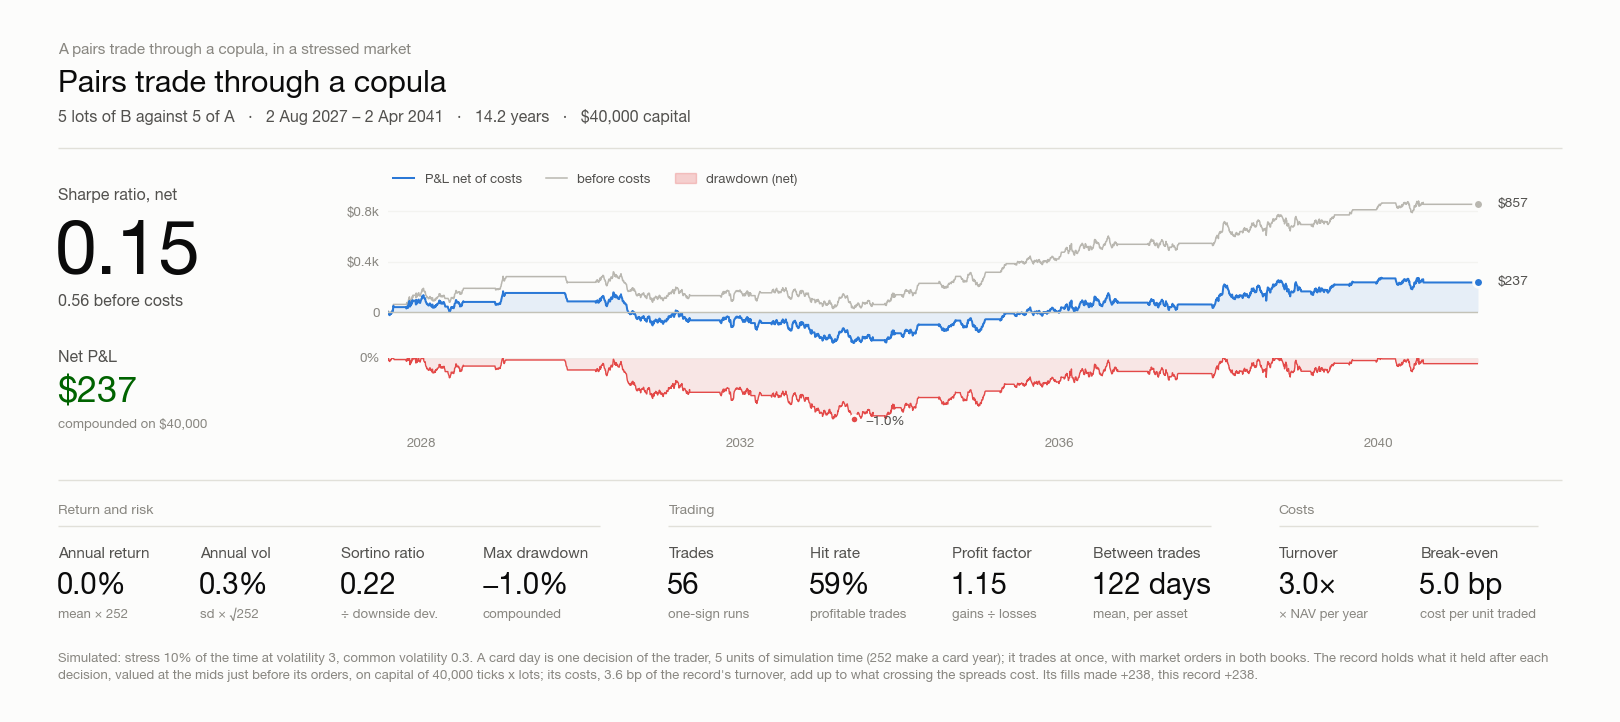

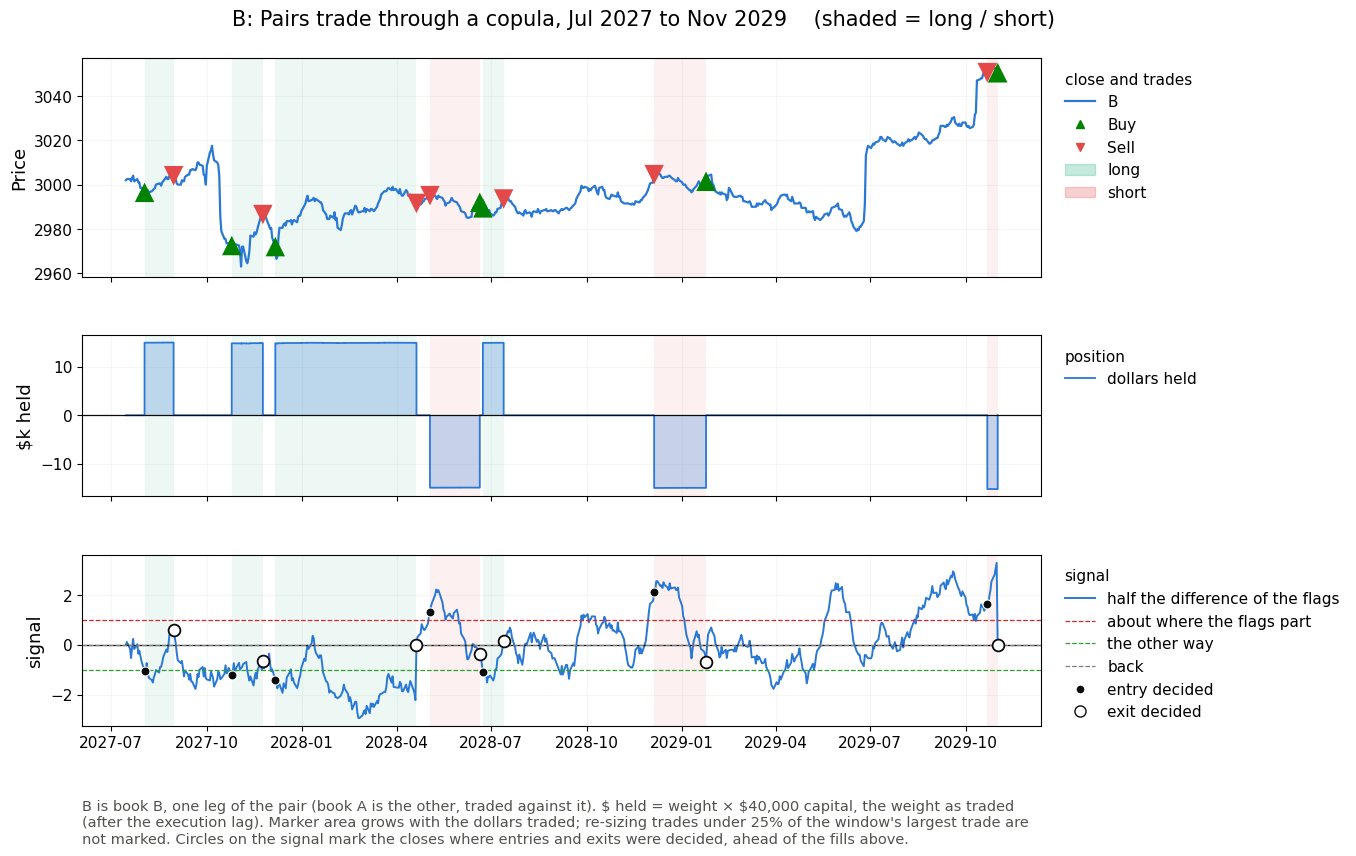

A last check: each card agrees with the fills: ['+806 and +806', '-194 and -194', '+238 and +238']


In [10]:
trader = CopulaTrader(window=400, trading=200, entry=1.0, exit=0.0, interval=5.0, size=5, record=True)
m = market(1, (trader,), **COPULA_MARKETS['stress, both ways'])
m.run(UNITS, every=1000.0)
agreement.append(card(trader, m, 'Pairs trade through a copula', '5 lots of B against 5 of A',
                      'A pairs trade through a copula, in a stressed market',
                      'stress 10% of the time at volatility 3, common volatility 0.3',
                      'half the difference of the flags',
                      [(1.0, 'C3', 'about where the flags part'), (-1.0, 'C2', 'the other way'), (0.0, 'C7', 'back')],
                      start=400, end=1000, per_unit=5))
print('A last check: each card agrees with the fills:', [f'{a:+,.0f} and {b:+,.0f}' for a, b in agreement])

## 6. Fitting the Settings

Sections 2 and 5 looked at their levels and memories across the same runs that report them, and that flatters whichever comes first. The dashboard's Pairs view instead fits a trader's settings on training runs of their own, and compares each with the settings the user started from. Does that help on markets it has not seen?

The test is what the panel does, at its default lengths:

- **Train.** Each combination of the panel's proposed values trades alone in three new markets, over 10,000 units of time after the longest warm-up among them. That is one fit. There are five, on seeds of their own.
- **Choose**, by two rules: always the best; or the best only if it beats the starting settings by two standard errors of the difference, which the panel calls *clearly better*.
- **Test.** The settings chosen, and the starting ones, on 16 seeds none of them was chosen on, over 17,500 units.

In [11]:
ENTRIES = (1.5, 2.0, 2.5, 3.0)
# What the panel proposes for each kind (the values to try, and what they are tried with), and where it starts from.
FIT_KINDS = {
    'z-score': (PairsTrader, dict(exit=0.0, size=5), dict(window=(200, 400, 1000, 2000), entry=ENTRIES),
                dict(window=400, entry=2.0)),
    'Kalman': (KalmanTrader, dict(window=400, exit=0.0, size=5), dict(memory=(300.0, 1000.0, 3000.0), entry=ENTRIES),
               dict(memory=1000.0, entry=2.0)),
    'copula': (CopulaTrader, dict(window=400, interval=5.0, exit=0.0, size=5),
               dict(entry=(0.5, 1.0, 1.5, 2.0, 3.0), trading=(100, 200, 400)), dict(entry=1.0, trading=200)),
}
FIT_MARKETS = {'common volatility 1': dict(volatility=1.0), 'stress both ways': STRESS}
FITS, RUNS, TRAIN_SPAN, TEST_SPAN = 5, 3, 10_000.0, 17_500.0
TEST_SEEDS = range(1001, 1017)  # none of these settings was chosen on them


def candidates_of(kind):
    grid = FIT_KINDS[kind][2]
    return [dict(zip(grid, combo, strict=True)) for combo in itertools.product(*grid.values())]


def setting(values):
    return ', '.join(f'{name} {value:g}' for name, value in values.items())


def scored(kind, values, market_name, seed, span):
    # One trader alone in a market, after the same warm-up for all of its kind, over the same span.
    make, fixed, _, _ = FIT_KINDS[kind]
    burn = max(make(**fixed, **v).warm_up for v in candidates_of(kind))
    trader = make(**fixed, **values)
    return score_trader(market(seed, (trader,), **FIT_MARKETS[market_name]), trader, burn, span)['pnl']


def training_row(kind, values, market_name, fit, run):
    return {'kind': kind, 'market': market_name, 'setting': setting(values), 'fit': fit, 'run': run,
            'P&L': scored(kind, values, market_name, 100_000 + 1_000 * fit + run, TRAIN_SPAN)}


def choose(runs, yours):
    # A fit's two choices, from its runs: the best, and the best only if it clearly beats the starting settings.
    wide = runs.pivot(index='run', columns='setting', values='P&L')
    best = wide.mean().idxmax()
    difference = wide[best] - wide[yours]
    clearly = best != yours and difference.mean() > 2 * difference.std() / math.sqrt(len(difference))
    return best, best if clearly else yours


training = pd.DataFrame(Parallel(n_jobs=-1)(
    delayed(training_row)(kind, values, market_name, fit, run) for market_name in FIT_MARKETS for kind in FIT_KINDS
    for values in candidates_of(kind) for fit in range(FITS) for run in range(RUNS)))
fit_choices = []
for (market_name, kind, fit), runs in training.groupby(['market', 'kind', 'fit'], sort=False):
    yours = setting(FIT_KINDS[kind][3])
    fit_choices.append(dict(zip(('market', 'kind', 'fit', 'yours', 'best', 'guarded'),
                           (market_name, kind, fit, yours, *choose(runs, yours)), strict=True)))
fit_choices = pd.DataFrame(fit_choices)


def test_row(kind, label, market_name, seed):
    values = next(v for v in candidates_of(kind) if setting(v) == label)
    return {'kind': kind, 'market': market_name, 'setting': label, 'seed': seed,
            'P&L': scored(kind, values, market_name, seed, TEST_SPAN)}


wanted = sorted({(c.kind, label, c.market) for c in fit_choices.itertuples() for label in (c.yours, c.best, c.guarded)})
tests = pd.DataFrame(Parallel(n_jobs=-1)(delayed(test_row)(kind, label, market_name, seed)
                                         for kind, label, market_name in wanted for seed in TEST_SEEDS))
pnl_by_seed = tests.pivot_table(index='seed', columns=['market', 'kind', 'setting'], values='P&L')


def rule_row(market_name, kind, c):
    # A rule's result: the mean over the fits of what it chose, on each test seed, against the starting settings.
    table = pnl_by_seed[market_name, kind]
    theirs = table[c.yours.iloc[0]]
    row = {'market': market_name, 'kind': kind, 'yours': theirs.mean(), 'se': theirs.std() / math.sqrt(len(theirs))}
    for rule, picks in (('best', c.best), ('clearly', c.guarded)):
        gain = table[list(picks)].mean(axis=1) - theirs
        row |= {f'{rule}: P&L': theirs.mean() + gain.mean(), f'{rule}: gain': gain.mean(),
                f'{rule}: se': gain.std() / math.sqrt(len(gain))}
    moved = c[c.guarded != c.yours]
    row |= {'best beat yours': int(sum(table[label].mean() > theirs.mean() for label in c.best)),
            'called clearly better': len(moved),
            'and it was': int(sum(table[label].mean() > theirs.mean() for label in moved.guarded))}
    return row


fit_results = pd.DataFrame([rule_row(market_name, kind, c) for (market_name, kind), c
                            in fit_choices.groupby(['market', 'kind'], sort=False)]).set_index(['market', 'kind'])
print(f'{len(training):,} training runs, {len(tests):,} test runs. P&L over {TEST_SPAN:,.0f} units on '
      f'{len(TEST_SEEDS)} seeds; of {FITS} fits in each row:')
print(fit_results.round(0).to_string())
print()
for (market_name, kind), c in fit_choices.groupby(['market', 'kind'], sort=False):
    counts = '; '.join(f'{label} ({n})' for label, n in c.best.value_counts().items())
    print(f'{market_name}, {kind}: best in training was {counts}')

1,290 training runs, 320 test runs. P&L over 17,500 units on 16 seeds; of 5 fits in each row:
                             yours    se  best: P&L  best: gain  best: se  clearly: P&L  clearly: gain  clearly: se  best beat yours  called clearly better  and it was
market              kind                                                                                                                                               
common volatility 1 z-score  587.0  42.0     1255.0       668.0      47.0        1255.0          668.0         47.0                5                      5           5
                    Kalman   682.0  56.0      936.0       253.0      49.0         784.0          101.0         20.0                5                      2           2
                    copula   277.0  49.0      260.0       -17.0      43.0         272.0           -5.0         23.0                1                      2           1
stress both ways    z-score  278.0  45.0      856.0       578.0   

**The z-score has the most to gain.** Its window of 400 is short here, and every fit lengthens it, to 1,000 or 2,000 decisions, for about two to three times the P&L on the fresh seeds. Fitted, it is the best of the three in both markets. The panel calls these clearly better every time, and every time rightly.

**The Kalman trader gains less, and the panel's rule passes up some of it.** The fits agree on a memory of 3,000. That beats the start on the fresh seeds in every fit, but by little enough that the three training runs cannot always show it, so the rule stays with the start about half the time: *not clearly better* does not mean no better. When it does call one, it is right.

**The copula has nothing to find.** Its fits choose settings all over the grid, a sign that they are close to alike, and the best in training does no better than the start on the fresh seeds. The rule keeps the start most of the time, and that costs it about nothing. Its $D = 1$ came from looking at seeds 1 to 8 (section 5), so this does not show that $D = 1$ beats its neighbors, only that three training runs find nothing better: the settings are too close together for them to tell.

**One caution.** The training runs compare candidates on the same seeds, and it is tempting to read that as the same markets. It is not, as a single seed shows:

In [12]:
def common_factor(window, seed=5, units=3_000):
    trader = PairsTrader(window=window, entry=2.0, exit=0.0, size=5)
    frame = market(seed, (trader,), volatility=1.0).run(units)
    return frame.common.to_numpy(), float(frame.time[frame.pos_b_0 != 0].iloc[0])


shorter, first_trade = common_factor(200)
longer, _ = common_factor(400)
apart = np.abs(shorter - longer)
print(f'Two z-scores on one seed, windows 200 and 400. The first trade comes at time {first_trade:,.0f}.')
print(f'Largest difference between their common factors before it: {apart[:int(first_trade) - 1].max():.3f}.')
print(f'Difference at the end: {apart[-1]:.1f}. Correlation of their changes from time 500 on: '
      f'{np.corrcoef(np.diff(shorter)[500:], np.diff(longer)[500:])[0, 1]:+.3f}.')
print()
shared = {}
for (market_name, kind), runs in training.groupby(['market', 'kind'], sort=False):
    by_run = runs.pivot_table(index=['fit', 'run'], columns='setting', values='P&L')
    together = np.corrcoef(by_run.to_numpy().T)
    shared[market_name, kind] = together[np.triu_indices_from(together, 1)].mean()
print('Mean correlation, across seeds, between two candidates\' training P&L:')
print(pd.Series(shared).unstack().round(2).to_string())

Two z-scores on one seed, windows 200 and 400. The first trade comes at time 214.
Largest difference between their common factors before it: 0.000.
Difference at the end: 64.2. Correlation of their changes from time 500 on: -0.014.

Mean correlation, across seeds, between two candidates' training P&L:
                     Kalman  copula  z-score
common volatility 1    0.38    0.05     0.13
stress both ways       0.19   -0.00     0.07


**A seed gives two traders one market only until the first trade.** An order changes the books, so the rates, so what every later random number is used for, and from then on the two markets, common factor included, have nothing to do with each other. So candidates' results on a seed hardly move together: the correlations above are small, largest for the Kalman trader. Comparing them seed by seed takes out little of the luck. The comparison is still fair, and the standard errors, being measured from the differences, are still right. They are about as large as if the seeds had been different (at most a fifth smaller, for the Kalman trader), in this section and in section 5's differences alike. A random stream of their own for what is outside the traders' reach, the common factor and the books' own parts, might make these comparisons sharper; that is neither built nor tested here.

Here is what a fit finds for the z-score in a backtest's terms, under stress, on a seed that played no part in choosing it:

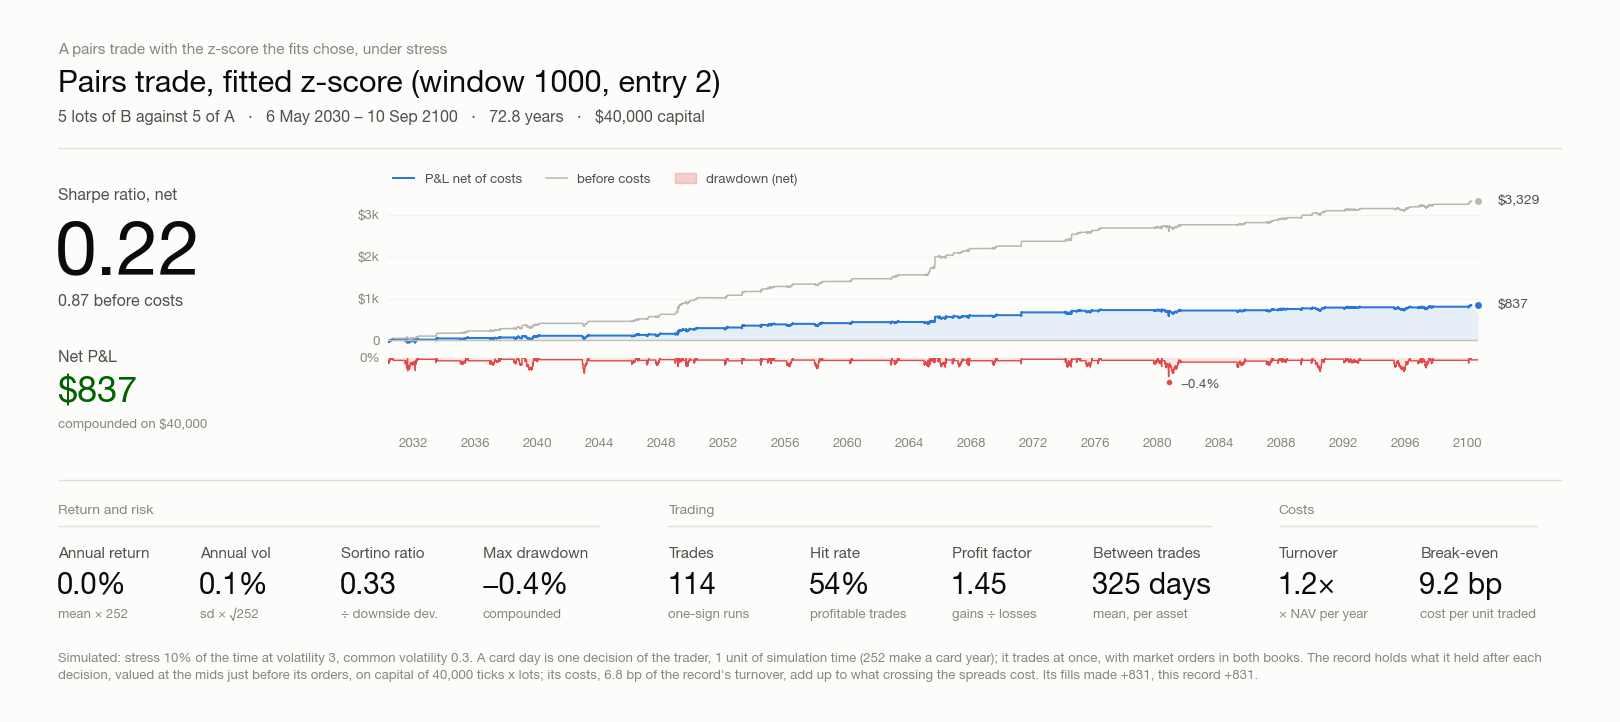

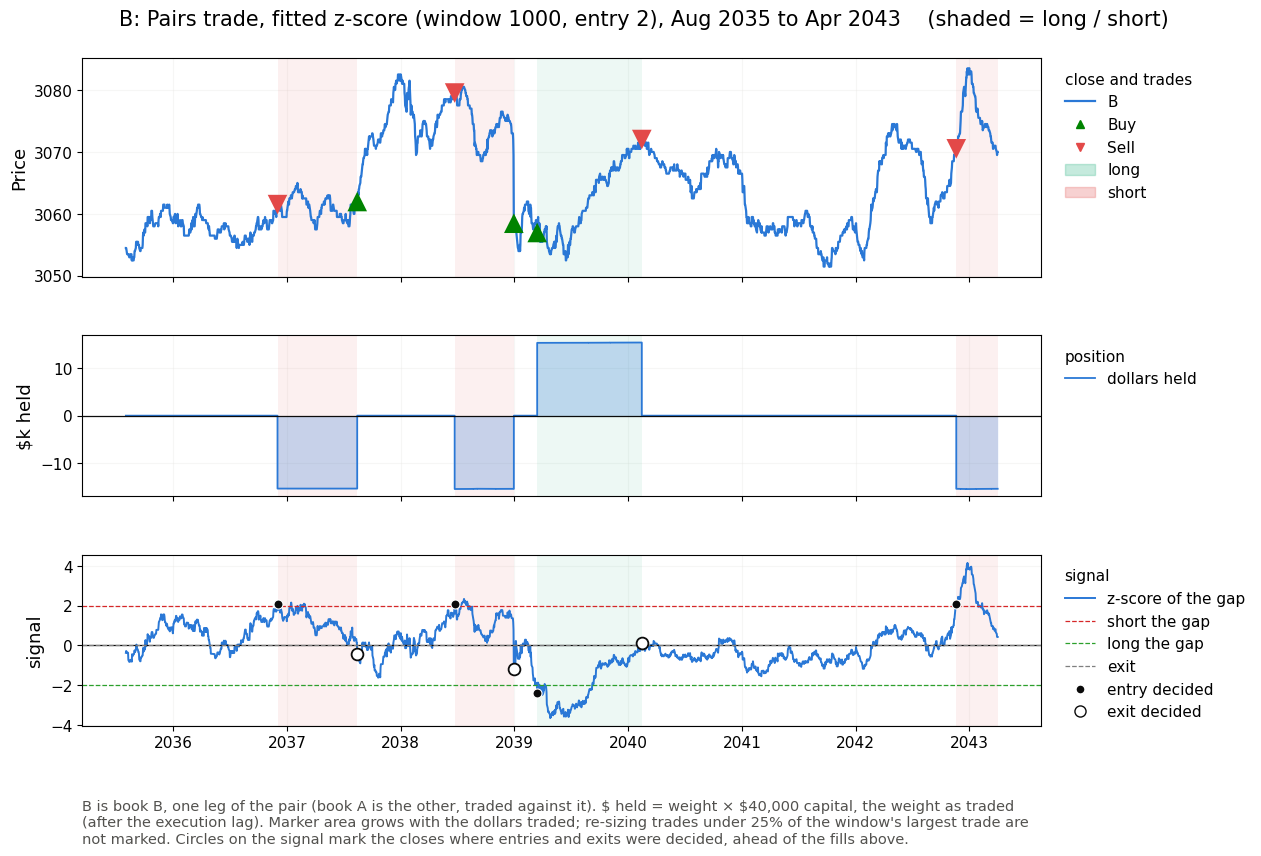

The card agrees with the fills: +831 and +831


In [13]:
choices = fit_choices[(fit_choices.market == 'stress both ways') & (fit_choices.kind == 'z-score')]
fitted = next(v for v in candidates_of('z-score') if setting(v) == choices.best.mode()[0])
trader = PairsTrader(**FIT_KINDS['z-score'][1], **fitted, record=True)
m = market(TEST_SEEDS[0], (trader,), **STRESS)
m.run(UNITS, every=1000.0)
entry = fitted['entry']
fills, record = card(trader, m, f"Pairs trade, fitted z-score ({setting(fitted)})", '5 lots of B against 5 of A',
                     'A pairs trade with the z-score the fits chose, under stress',
                     'stress 10% of the time at volatility 3, common volatility 0.3', 'z-score of the gap',
                     [(entry, 'C3', 'short the gap'), (-entry, 'C2', 'long the gap'), (0.0, 'C7', 'exit')],
                     start=2500, end=4500)
print(f'The card agrees with the fills: {fills:+,.0f} and {record:+,.0f}')

## 7. Conclusions

In [14]:
def row(frame, market_name, trader_name):
    return frame[(frame.market == market_name) & (frame.trader == trader_name)]


def said(values):
    values = values['P&L']
    return f'{values.mean():+,.0f} ({(values > 0).sum()} of {len(values)} seeds positive)'


fixed_fixed = row(hedge_frame, 'beta fixed, common 1', 'fixed hedge')
kalman_fixed = row(hedge_frame, 'beta fixed, common 1', 'Kalman')
fixed_slow = row(hedge_frame, 'beta drifts, common 1', 'fixed hedge')
perfect_slow = row(hedge_frame, 'beta drifts, common 1', 'perfect hedge')
kalman_slow = row(hedge_frame, 'beta drifts, common 1', 'Kalman')
fixed_thin = row(hedge_frame, 'beta drifts, common 2', 'fixed hedge')
kalman_thin = row(hedge_frame, 'beta drifts, common 2', 'Kalman')
fixed_fast = row(hedge_frame, 'beta drifts, common 2, deep', 'fixed hedge')
kalman_fast = row(hedge_frame, 'beta drifts, common 2, deep', 'Kalman')
perfect_fast = row(hedge_frame, 'beta drifts, common 2, deep', 'perfect hedge')
held_fast = row(hedge_frame, 'beta drifts, common 2, deep', 'Kalman, held')

print(f"- With beta fixed, learning the hedge costs money: {said(kalman_fixed)} against {said(fixed_fixed)} for the "
      f"same filter with the hedge frozen.")
print(f"- With beta drifting by 0.3 and a common volatility of 1, there is little to win: a perfect hedge makes "
      f"{said(perfect_slow)} and a fixed one {said(fixed_slow)}. The filter makes {said(kalman_slow)}.")
print(f"- With beta drifting by 0.5 and a common volatility of 2, costs decide it. In the standard books the filter "
      f"makes {kalman_thin['before costs'].mean():+,.0f} before costs and {kalman_thin['P&L'].mean():+,.0f} after, a "
      f"fixed hedge {fixed_thin['before costs'].mean():+,.0f} and {fixed_thin['P&L'].mean():+,.0f}.")
print(f"- In books four times as deep the filter pays: {said(kalman_fast)} against {said(fixed_fast)} for a fixed "
      f"hedge, under a ceiling of {said(perfect_fast)}.")
print(f"- Following the hedge while holding adds nothing measurable: {kalman_fast['P&L'].mean():+,.0f} against "
      f"{held_fast['P&L'].mean():+,.0f} for setting it on entry, in the market where the hedge matters most.")

picked = families.groupby('market', sort=False).family.agg(lambda f: f.value_counts().index[0])
share = families.groupby('market', sort=False).family.agg(lambda f: f.value_counts().iloc[0] / len(f))
print(f"- The copula finds the dependence that was built in: {picked['stress, both ways']} in "
      f"{share['stress, both ways']:.0%} of seeds under stress both ways, {picked['stress, falling']} in "
      f"{share['stress, falling']:.0%} under falling stress.")
print(f"- With no fresh start the flags drift, mostly through their margins: a median half-life of "
      f"{stats['half-life, one window'].median():,.0f}, or {stats['half-life, centered'].median():,.0f} with margins "
      f"centered on the whole run, against {stats['half-life of the gap'].median():,.0f} for the gap. Within a trading "
      f"period they follow the gap's change since the fresh start (correlation "
      f"{stats.iloc[:, -1].median():.2f}), and say nothing of where its mean is.")
print(f"- Over the four markets, the family chosen by AIC adds {gains['a Gaussian always'].mean():+.0f} a run to a "
      f"Gaussian always (se {gains['a Gaussian always'].std() / math.sqrt(len(gains['a Gaussian always'])):.0f}), and "
      f"{gains['no dependence'].mean():+.0f} to no dependence at all "
      f"(se {gains['no dependence'].std() / math.sqrt(len(gains['no dependence'])):.0f}).")
falling_z, falling_c = storms.loc[('falling', 'z-score, window 2,000')], storms.loc[('falling', 'copula, D = 1')]
print(f"- Under falling stress, {falling_z['time']:.0%} of the time, the long z-score does {falling_z['lots']:.0%} of "
      f"its lots, at {falling_z['a lot, stressed']:.1f} ticks a lot against {falling_z['a lot, calm']:.1f} in calm; "
      f"the copula does {falling_c['lots']:.0%}, at {falling_c['a lot, stressed']:.1f}: ranks cap the large moves.")
for name in COPULA_RUN_MARKETS:
    chosen = row(copula_frame, name, 'copula, D = 1')
    z_long = row(copula_frame, name, 'z-score, window 2,000')
    print(f"- {name}: the copula makes {said(chosen)}, at {chosen.costs.sum() / chosen.lots.sum():.2f} ticks a lot; "
          f"the z-score with a window of 2,000 {said(z_long)}, at {z_long.costs.sum() / z_long.lots.sum():.2f}.")
for (market_name, kind), r in fit_results.iterrows():
    print(f"- Fitted, {kind} in {market_name}, on fresh seeds: {r['yours']:+,.0f} from its start (se {r['se']:.0f}); "
          f"always taking the best in training {r['best: gain']:+,.0f} on that (se {r['best: se']:.0f}, better in "
          f"{r['best beat yours']:.0f} of {FITS} fits); taking it only when clearly better {r['clearly: gain']:+,.0f} "
          f"(se {r['clearly: se']:.0f}; called in {r['called clearly better']:.0f} of {FITS} fits, rightly in "
          f"{r['and it was']:.0f}).")

- With beta fixed, learning the hedge costs money: +655 (8 of 8 seeds positive) against +1,055 (8 of 8 seeds positive) for the same filter with the hedge frozen.
- With beta drifting by 0.3 and a common volatility of 1, there is little to win: a perfect hedge makes +941 (8 of 8 seeds positive) and a fixed one +915 (8 of 8 seeds positive). The filter makes +545 (8 of 8 seeds positive).
- With beta drifting by 0.5 and a common volatility of 2, costs decide it. In the standard books the filter makes +2,036 before costs and +5 after, a fixed hedge +456 and +16.
- In books four times as deep the filter pays: +702 (8 of 8 seeds positive) against +183 (4 of 8 seeds positive) for a fixed hedge, under a ceiling of +1,264 (8 of 8 seeds positive).
- Following the hedge while holding adds nothing measurable: +702 against +839 for setting it on entry, in the market where the hedge matters most.
- The copula finds the dependence that was built in: Student t in 100% of seeds under stress both ways, C

**Limitations.** The market was built to give each method something to find, and these options are one choice among many: a beta that jumps would favor a filter differently, and stress that hits one book more than the other would give a copula more to work with. The traders hold one pair, with market orders, in books where crossing costs more than a tick a lot, which is expensive: much of what separates them before costs goes to the spread, and passive execution could change the order. The perfect hedge is a ceiling only for this rule on this filter. Outside section 6, the entry levels and memories were looked at across these same runs, not fitted out of sample. And eight seeds are few when a common volatility of 2 makes the P&L this noisy: read each difference against its standard errors.